# Processing a Sentinel-2 image

This notebook runs GRS on one Sentinel-2 L1C image from Python and checks the result:

- the Level-1 image and its auxiliary data (CAMS file, optional DEM),
- the processing with {py:class}`grs.Process`, lazy until the product is written,
- the export of the L2A product as a Zarr store with overviews,
- maps of the remote-sensing reflectance $R_{rs}$, of the sunglint and of the aerosol optical
  thickness retrieved from the image,
- the pixel classification (`flags`) and the `mask` of the valid water pixels,
- the $R_{rs}$ spectra of a few pixels.

The image is the Sentinel-2B acquisition of 2020-04-11 over the Loire estuary and the Bay of Biscay
(tile 30TWT), with clear and turbid waters and sunglint offshore.

## 1. Libraries

In [1]:
import os
import time
import warnings

# deprecation notices of the dependencies, not useful here
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', message='Consolidated metadata')

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from pyproj import Transformer

from osgeo import gdal
import GRSdriver
import grs

gdal.UseExceptions()

opj = os.path.join
print(f'grs:       {grs.__version__}')
print(f'GRSdriver: {GRSdriver.__version__}')

grs:       3.1.0
GRSdriver: 1.0.10


## 2. Settings

GRS needs the Level-1 image and the CAMS file of the month of the acquisition (see the
{doc}`CAMS tutorial <../auxdata>`); the look-up tables are set in `grs/config.yml` (see
{doc}`../../installation`). A DEM (GeoTIFF subset to the tile) improves the surface pressure over
inland waters; it is not needed over the sea.

In [2]:
# settings: edit the paths to run the notebook on your own data
l1c_file = ('/data/satellite/Sentinel-2/L1C/30TWT/2020/04/11/'
            'S2B_MSIL1C_20200411T110619_N0500_R137_T30TWT_20230509T002033.SAFE')
cams_file = '/data/cams/world/cams_forecast_2020-04.nc'
dem_file = None

odir = '/data/satellite/Sentinel-2/test/grs_tutorial'
product = opj(odir, 'S2B_MSIL2AGRS_20200411T110619_T30TWT_tutorial.zarr')   # .zarr or .nc

resolution = 20        # m (10, 20 or 60)
aot_resolution = 240   # m, grid of the aerosol retrieval, multiple of resolution

## 3. Processing

{py:meth}`~grs.grs_process.Process.execute` reads the image, the CAMS data and the look-up tables,
classifies the pixels, chooses the aerosol model and retrieves the aerosol optical thickness on the
coarse grid (`aot_resolution`): one value per block of `aot_chunk` coarse pixels (default 256), then
smoothed with a weighted mean over `aot_smoothing_blocks` blocks (default 3, weights: number of water
pixels of the blocks). The correction of every pixel is then set up **lazily** with dask:
`process.l2a.l2_prod` describes the product, but nothing is computed yet.

In [3]:
t0 = time.time()
process = grs.Process()
process.execute(l1c_file,
                cams_file=cams_file,
                dem_file=dem_file,
                resolution=resolution,
                aot_resolution=aot_resolution,
                odir=product)
print(f'execute: {time.time() - t0:.0f} s')
process.l2a.l2_prod

INFO:root:Open L1C Sentinel 2 image and compute angle parameters


INFO:root:pass raw image as grs product object


INFO:root:get CAMS auxilliary data


INFO:root:flagging from l1c data


INFO:root:OmniCloudMask processing on 1830 x 1830 pixels (60 m)


...

INFO:root:Update flags and create mask from recipe


INFO:root:construct final product


INFO:root:construct l2a


execute: 459 s


<xarray.Dataset> Size: 2GB
Dimensions:             (x: 5490, y: 5490, wl: 11)
Coordinates:
  * x                   (x) float64 44kB 5e+05 5e+05 ... 6.098e+05 6.098e+05
  * y                   (y) float64 44kB 5.3e+06 5.3e+06 ... 5.19e+06 5.19e+06
  * wl                  (wl) int64 88B 443 490 560 665 705 ... 842 865 1610 2190
    central_wavelength  (wl) float32 44B 442.2 492.4 ... 1.61e+03 2.186e+03
    time                datetime64[ns] 8B 2020-04-11T11:06:19
    spatial_ref         int64 8B 0
Data variables:
    Rrs                 (wl, y, x) float32 1GB dask.array<chunksize=(11, 512, 512), meta=np.ndarray>
    BRDFg               (y, x) float32 121MB dask.array<chunksize=(512, 512), meta=np.ndarray>
    aot550              (y, x) float32 121MB dask.array<chunksize=(512, 512), meta=np.ndarray>
    wind                (y, x) float64 241MB dask.array<chunksize=(512, 512), meta=np.ndarray>
    mask                (y, x) uint8 30MB dask.array<chunksize=(512, 512), meta=np.ndarray>
    vza                 (y, x) float32 121MB dask.array<chunksize=(1024, 1024), meta=np.ndarray>
    sza                 (y, x) float32 121MB dask.array<chunksize=(1024, 1024), meta=np.ndarray>
    raa                 (y, x) float32 121MB dask.array<chunksize=(1024, 1024), meta=np.ndarray>
    flags               (y, x) uint32 121MB dask.array<chunksize=(512, 512), meta=np.ndarray>
    dem                 (y, x) float32 121MB dask.array<chunksize=(1024, 1024), meta=np.ndarray>
Attributes: (12/78)
    path:                                /tmp/tmpl8cf8b0z/tmp_20200411T110619...
    long_name:                           CA BLUE GREEN RED VRE_1 VRE_2 VRE_3 ...
    constellation:                       Sentinel-2
    constellation_id:                    S2
    product_path:                        /data/satellite/Sentinel-2/L1C/30TWT...
    product_name:                        S2B_MSIL1C_20200411T110619_N0500_R13...
    ...                                  ...
    vis_swir_index_threshold:            0.0
    hcld_threshold:                      0.003
    dirdata:                             /data/grs/grsdata
    abs_gas_file:                        /home/harmel/Dropbox/Dropbox/work/gi...
    water_vapor_transmittance_file:      /home/harmel/Dropbox/Dropbox/work/gi...
    GRSdriver_version:                   1.0.9

The aerosol model chosen from the CAMS spectral aerosol optical depth, and the size of the AOT grid:

In [4]:
{key: process.l2a.l2_prod.attrs[key] for key in ('opac_model', 'aot_resolution')}

{'opac_model': np.str_('COAV_rh70'), 'aot_resolution': 240}

{py:meth}`~grs.grs_process.Process.write_output` computes the product block by block and writes it:
the format follows the extension of `odir` (`.zarr`: Zarr store with overviews, `.nc`: NetCDF), see
{doc}`../../usage`.

In [5]:
t0 = time.time()
process.write_output()
print(f'write_output: {time.time() - t0:.0f} s')
print(sorted(os.listdir(product)))

INFO:root:export final product


INFO:root:export into encoded zarr


write_output: 61 s
['0', '1', '2', '3', '4', 'ancillary', 'zarr.json']


## 4. Results

The written product is reopened from the Zarr store (full resolution: group `'0'`; ancillary data:
group `'ancillary'`).

In [6]:
l2a = xr.open_zarr(product, group='0')
anc = xr.open_zarr(product, group='ancillary')

epsg = l2a.rio.crs.to_epsg()
proj = ccrs.UTM(epsg % 100, southern_hemisphere=epsg // 100 == 327)
water = l2a.mask == 0

### Remote-sensing reflectance

True-colour composite of $R_{rs}$ ($sr^{-1}$) for all the processed pixels and for the valid water
pixels only (`mask == 0`):

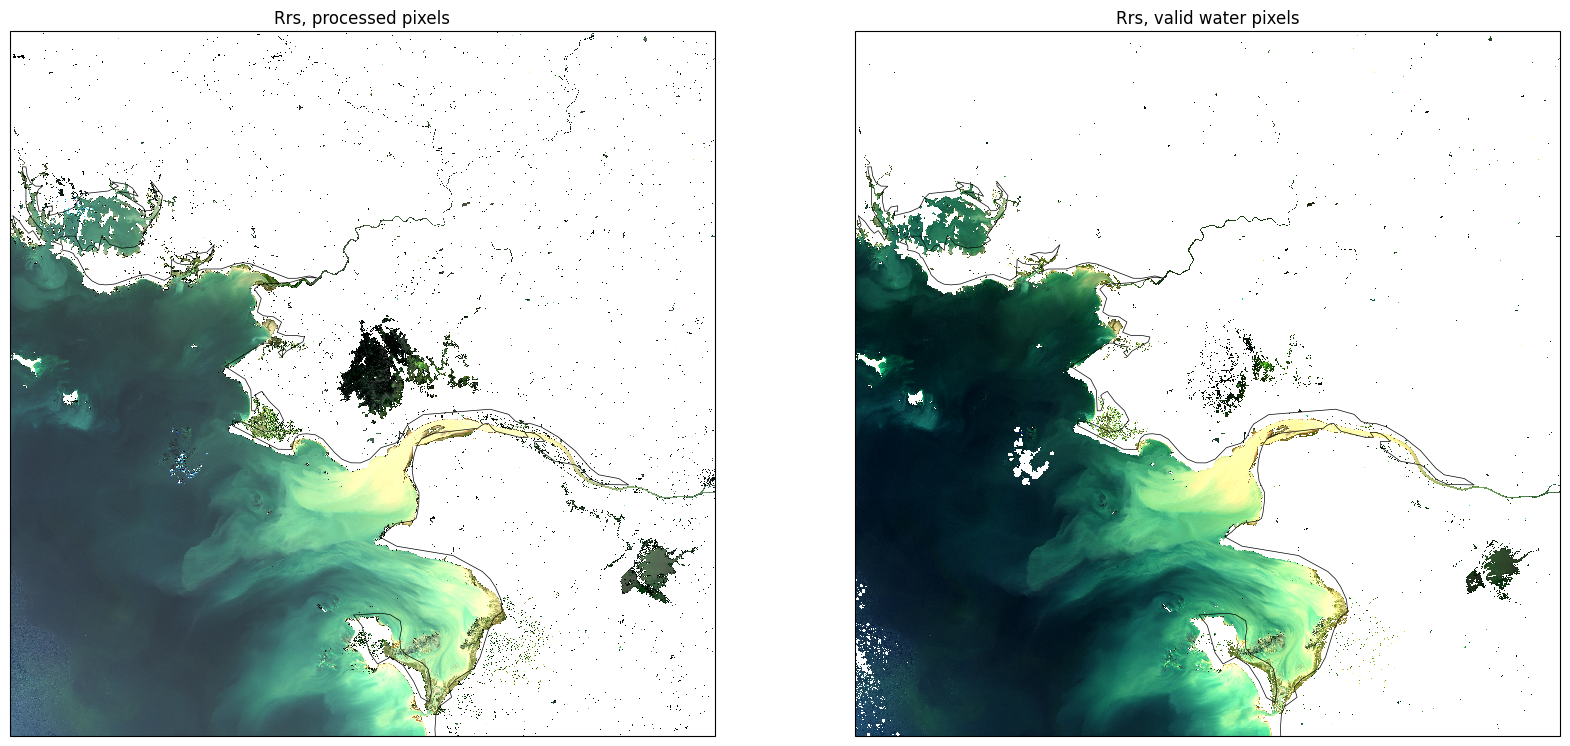

In [7]:
rgb = l2a.Rrs.sel(wl=[665, 560, 490])
fig, axs = plt.subplots(1, 2, figsize=(20, 10), subplot_kw={'projection': proj})
rgb.plot.imshow(rgb='wl', robust=True, ax=axs[0], transform=proj)
rgb.where(water).plot.imshow(rgb='wl', robust=True, ax=axs[1], transform=proj)
axs[0].set_title('Rrs, processed pixels')
axs[1].set_title('Rrs, valid water pixels')
for ax in axs:
    ax.coastlines('10m', linewidth=0.5)

### Sunglint and aerosols

`BRDFg` is the sunglint reflectance estimated in the SWIR bands and removed from all the bands (see
{doc}`../../methods`); `aot550` is the aerosol optical thickness at 550 nm retrieved from the image,
to compare with the CAMS forecast used as first guess (note the different colour scales: on this clear
day, the AOT retrieved from the image is much lower than the CAMS forecast):

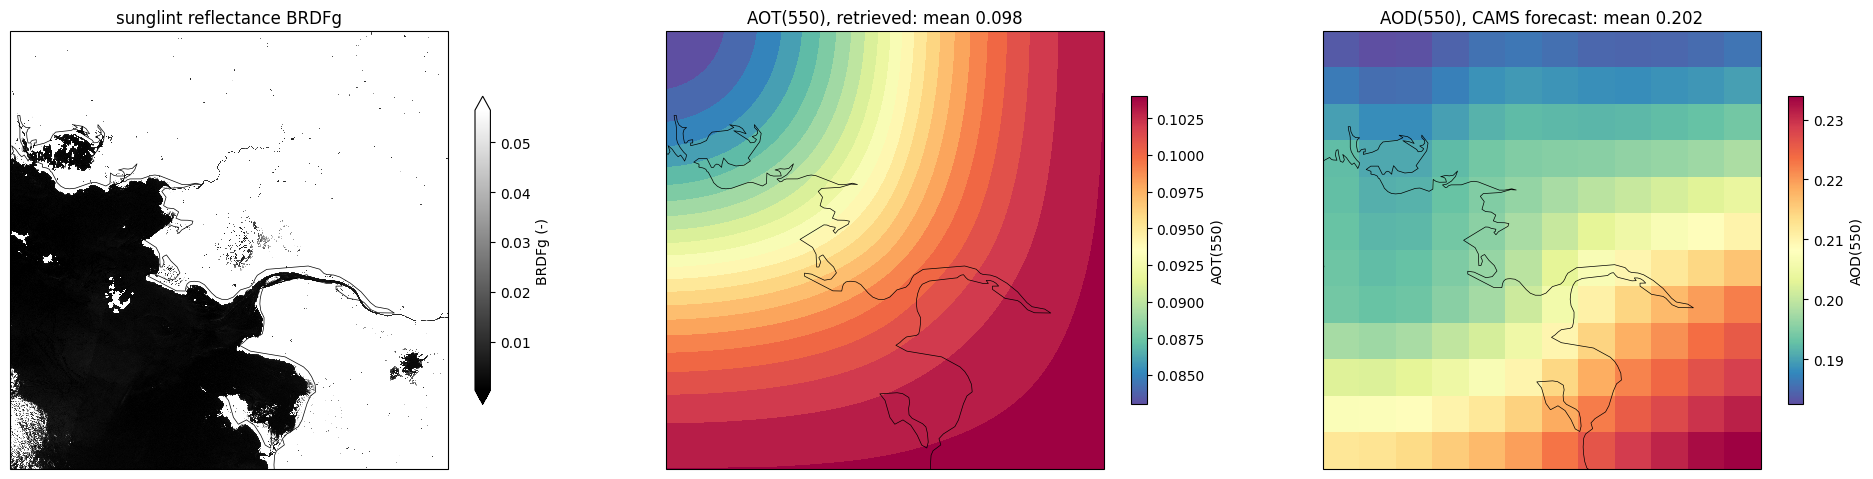

In [8]:
fig, axs = plt.subplots(1, 3, figsize=(24, 8), subplot_kw={'projection': proj})
l2a.BRDFg.where(water).plot.imshow(ax=axs[0], transform=proj, cmap='gray', robust=True,
                                   cbar_kwargs={'shrink': 0.5, 'label': 'BRDFg (-)'})
axs[0].set_title('sunglint reflectance BRDFg')
l2a.aot550.plot.imshow(ax=axs[1], transform=proj, cmap='Spectral_r',
                       cbar_kwargs={'shrink': 0.5, 'label': 'AOT(550)'})
axs[1].set_title(f'AOT(550), retrieved: mean {float(l2a.aot550.mean()):.3f}')
anc.aod550.plot.imshow(x='xc', y='yc', ax=axs[2], transform=proj, cmap='Spectral_r',
                       cbar_kwargs={'shrink': 0.5, 'label': 'AOD(550)'})
axs[2].set_title(f'AOD(550), CAMS forecast: mean {float(anc.aod550.mean()):.3f}')
for ax in axs:
    ax.coastlines('10m', linewidth=0.5)

## 5. Pixel classification

The `flags` bit field records the tests made on each pixel (clouds, water indices, cirrus, negative
$R_{rs}$...), with their names in its attributes; the `mask` combines them into valid (0) / rejected
(1) pixels. The proportion of the image raised by each flag:

In [9]:
flags = l2a.flags.load()
names = list(flags.attrs['flag_names'])
stats = pd.DataFrame({'name': names, 'description': flags.attrs['flag_descriptions']})
stats['proportion (%)'] = [float(((flags & (1 << bit)) > 0).mean()) * 100 for bit in range(len(names))]
stats = stats[stats.name != 'None']
stats.index.name = 'bit'
stats.round(2)

,name,description,proportion (%)
bit,,,
0,nodata,nodata in input image,0.00
1,cloud_p06,low confidence cloud mask from s2cloudless wit...,0.55
2,cloud_p08,high confidence cloud mask from s2cloudless wi...,0.14
3,water_swir_visible_index,water mask from normalized index from swir and...,36.00
4,water_red_visible_index,water mask from normalized index from nir and ...,35.06
5,thin_cirrus,"thin cirrus mask from cirrus band, threshold 0...",0.15
6,opac_cirrus,"opac cirrus mask from cirrus band, threshold 0...",0.06
7,high_swir,"high swir (bright cloud, too bright reflection...",5.58
8,surfwater_land,land mask from surfwater input file,0.00


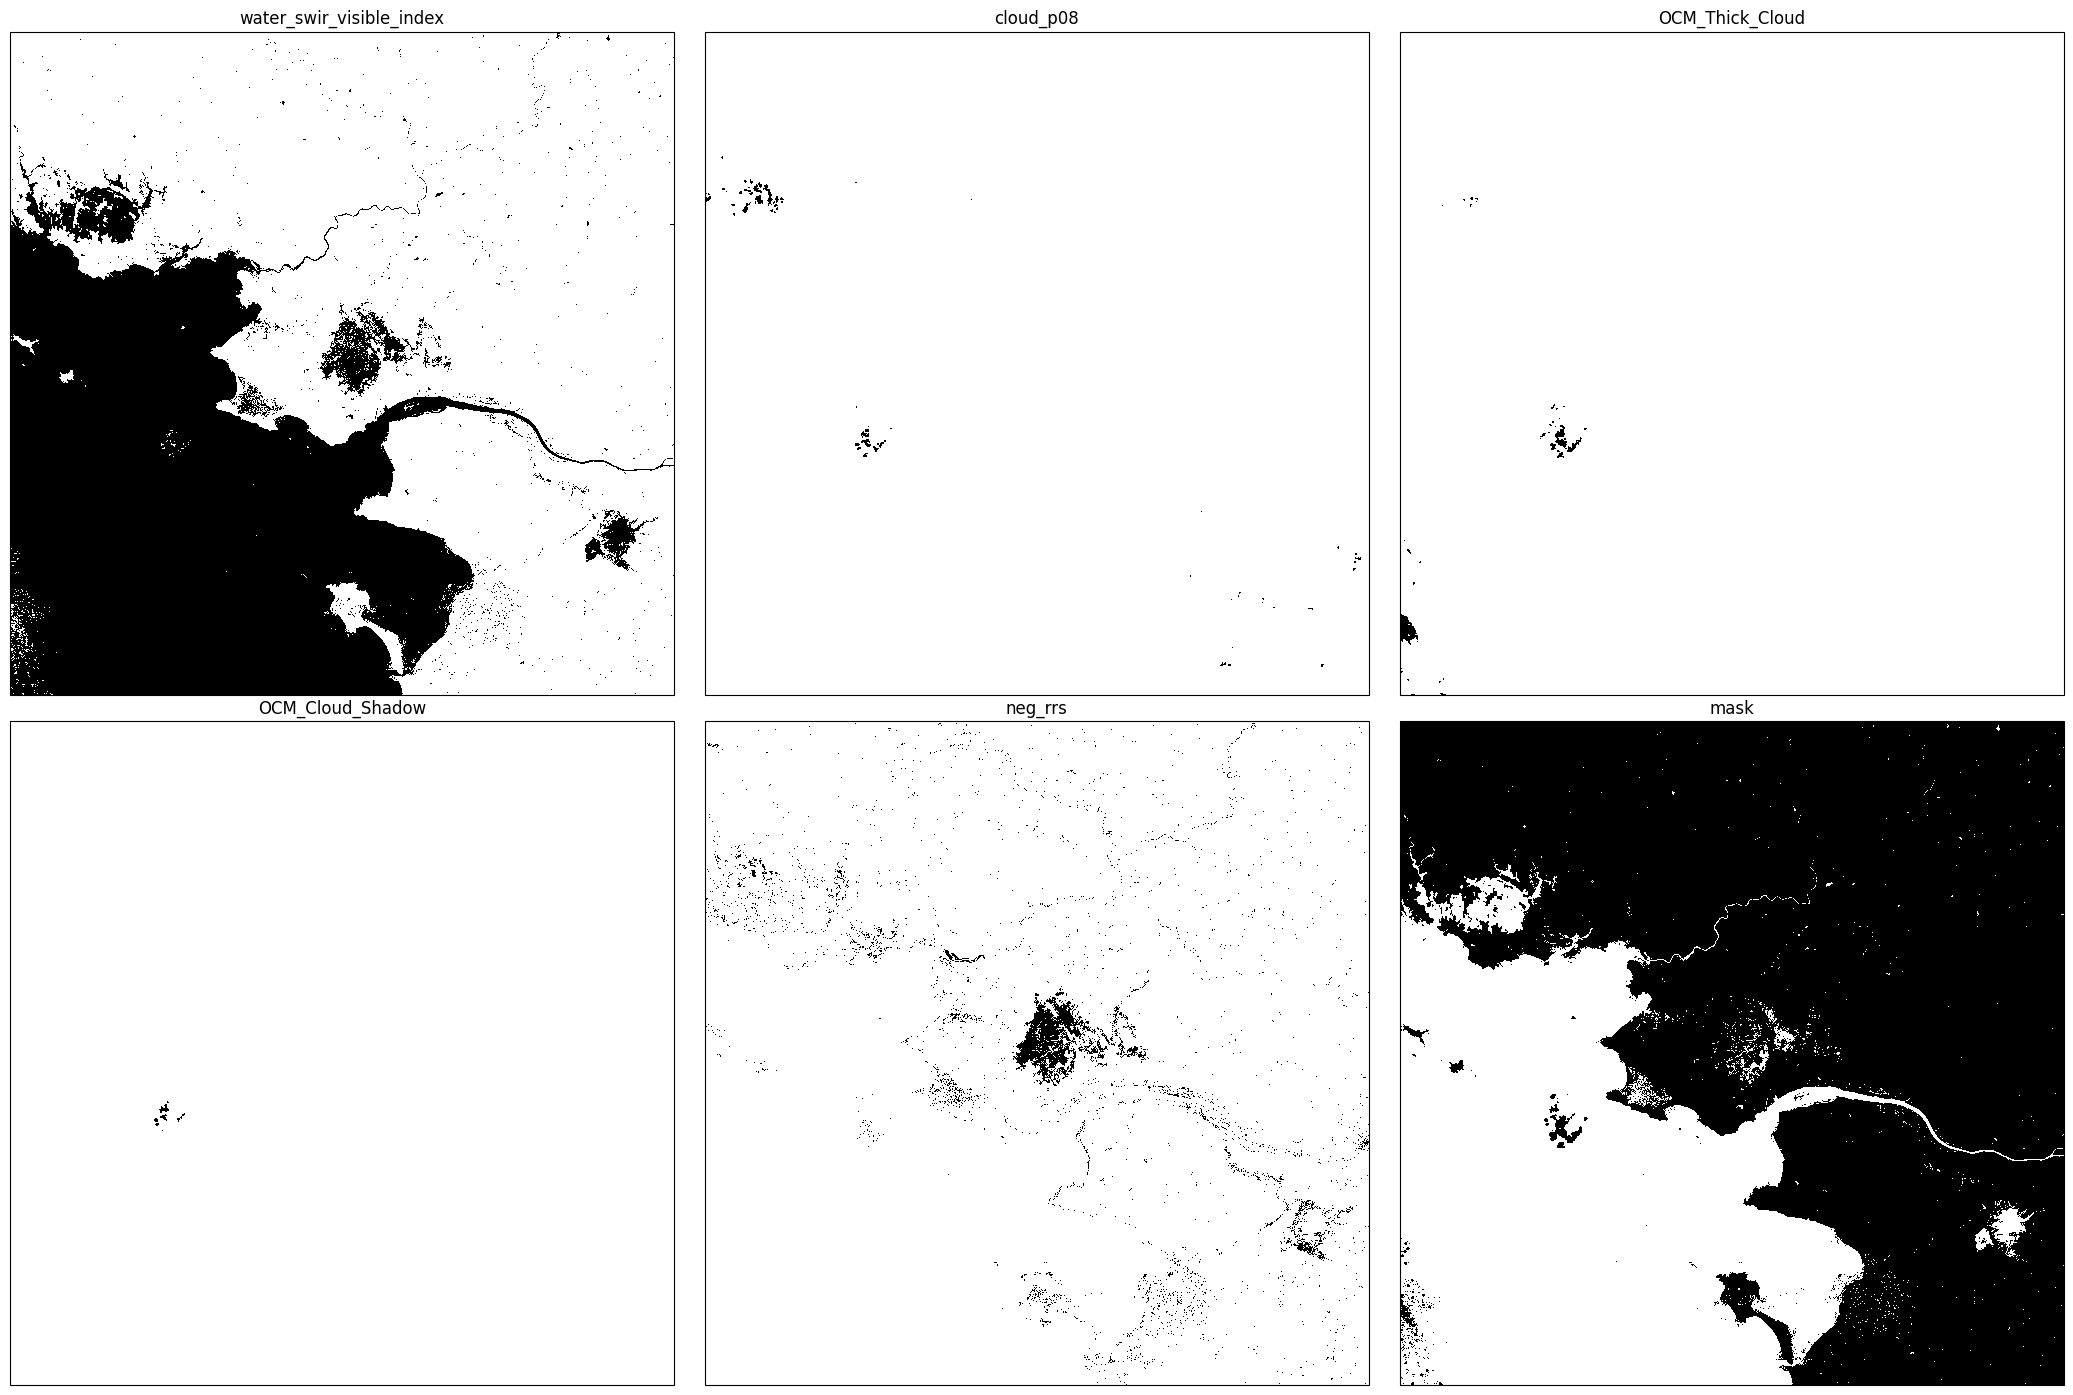

In [10]:
def flag(name):
    return (flags & (1 << names.index(name))) > 0


selection = ['water_swir_visible_index', 'cloud_p08', 'OCM_Thick_Cloud', 'OCM_Cloud_Shadow', 'neg_rrs']
selection = [name for name in selection if name in names]
fig, axs = plt.subplots(2, 3, figsize=(21, 14), subplot_kw={'projection': proj})
for ax, name in zip(axs.ravel(), selection + ['mask']):
    da = l2a.mask if name == 'mask' else flag(name)
    da.plot.imshow(ax=ax, transform=proj, add_colorbar=False, cmap='Greys')
    ax.set_title(name)
for ax in axs.ravel()[len(selection) + 1:]:
    ax.set_axis_off()
plt.tight_layout()

## 6. Spectra

$R_{rs}$ spectra of a few water pixels (longitude, latitude), from the turbid Loire estuary to the open
sea:

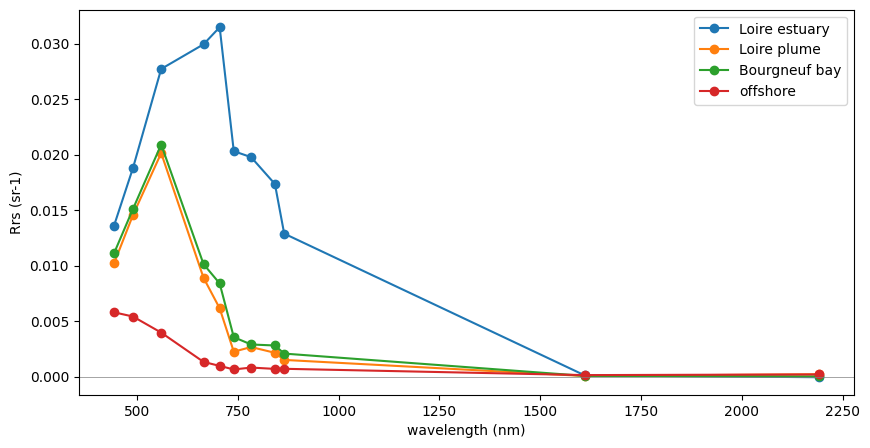

In [11]:
points = {'Loire estuary': (-2.18, 47.27), 'Loire plume': (-2.4, 47.18),
          'Bourgneuf bay': (-2.2, 47.08), 'offshore': (-2.8, 47.1)}

to_utm = Transformer.from_crs(4326, epsg, always_xy=True)
fig, ax = plt.subplots(figsize=(10, 5))
for name, (lon, lat) in points.items():
    x, y = to_utm.transform(lon, lat)
    l2a.Rrs.where(water).sel(x=x, y=y, method='nearest').plot(ax=ax, marker='o', label=name)
ax.axhline(0, color='grey', lw=0.5)
ax.set(xlabel='wavelength (nm)', ylabel='Rrs (sr-1)', title='')
ax.legend()

## 7. Command line

The same processing from a terminal (the output directory and name are built from the input name,
see {doc}`../../usage`):

```bash
grs S2B_MSIL1C_20200411T110619_N0500_R137_T30TWT_20230509T002033.SAFE \
    --cams_file cams_forecast_2020-04.nc --resolution 20 --odir /data/satellite/Sentinel-2/L2A
```

To explore the product interactively, see the {doc}`visualization tutorials <../visualization>`.